# Actividad 2026 — Q-learning: resolver, intervenir y auditar

**Actividad formativa de clase: sin nota ni entrega obligatoria.** El único TP del curso es Decision Transformer.

Leer la consigna en `../actividades/q_learning/CONSIGNA.md`. Adaptación original del [hands-on de Hugging Face](https://huggingface.co/learn/deep-rl-course/unit2/hands-on). El entorno y evaluación están provistos; completar la actualización y el análisis. No se requiere IA, GPU ni cuenta en el Hub.

Instalar `requirements.txt` en un entorno Python 3.11–3.13. En Colab subir este notebook y `experimentos.py`, e instalar `gymnasium==1.2.1 numpy==2.3.4 matplotlib==3.10.7`. No ejecutar la instalación del repo en una Jetson.

**Versión docente ejecutada:** incluye la solución, contraejemplos y trayectorias. El notebook estudiantil conserva la actualización como ejercicio.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
candidates = [Path.cwd(), Path.cwd() / "2026/actividades/q_learning", Path.cwd() / "actividades/q_learning"]
BASE = next((p for p in candidates if (p / "experimentos.py").exists()), None)
if BASE is None:
    raise FileNotFoundError("Abrir desde la raíz del repo o desde 2026/actividades/q_learning; se necesita experimentos.py")
sys.path.insert(0, str(BASE.resolve()))
from experimentos import numerical_checks, run_suite
import gymnasium as gym
print("Gymnasium", gym.__version__, "NumPy", np.__version__)


Gymnasium 1.2.1 NumPy 2.3.4


## 1. Registrar predicciones

Antes de correr, anotar dos predicciones sobre el lago resbaladizo y el bonus por permanecer vivo. ¿Qué resultado las refutaría? La hoja `INFORME_TEMPLATE.md` es opcional.


## 2. Actualización

Para un corte externo por tiempo: $r + \gamma(1-\mathbb{1}_{terminated})\max_{a'}Q(s',a')$.

La función debe **devolver el nuevo valor escalar**, sin modificar la tabla. `truncated` se entrega para que expliquen por qué no se usa como máscara terminal aquí.

In [2]:
def q_update(q, state, action, reward, next_state, terminated, truncated, alpha, gamma):
    target = reward + gamma * (not terminated) * q[next_state].max()
    return q[state, action] + alpha * (target - q[state, action])


In [3]:
numerical_checks(q_update)


Tres contraejemplos numéricos verificados.


## 3. Corridas

`demo`: una semilla, 3.000 pasos, 30 episodios para verificar instalación. `completo` (ampliación optativa): cinco semillas, 100.000 pasos y 100 episodios por política/configuración. Seleccionar hiperparámetros con validación y usar test una vez después de fijarlos. Las métricas de evaluación usan recompensa original y no actualizan Q.

La configuración de entrenamiento está explícita en `experimentos.py`; si la cambian, declarar y registrar la modificación.

In [4]:
MODE = "demo"  # Cambiar a "completo" para el experimento ampliado.
SPLIT = "validation"  # Usar "test" solo con decisiones ya fijadas.
steps = 3000 if MODE == "demo" else 100000
seeds = [11] if MODE == "demo" else [11, 22, 33, 44, 55]
episodes = 30 if MODE == "demo" else 100
results = run_suite(q_update, steps=steps, seeds=seeds, episodes=episodes,
                    split=SPLIT, output=BASE / "outputs" / (MODE + "_" + SPLIT))


lake_determinista {"trained": {"return": {"mean": 1.0, "seed_std": null}, "success": {"mean": 1.0, "seed_std": null}, "length": {"mean": 6.0, "seed_std": null}, "truncated": {"mean": 0.0, "seed_std": null}}, "random": {"return": {"mean": 0.03333333333333333, "seed_std": null}, "success": {"mean": 0.03333333333333333, "seed_std": null}, "length": {"mean": 7.533333333333333, "seed_std": null}, "truncated": {"mean": 0.0, "seed_std": null}}}
lake_resbaladizo {"trained": {"return": {"mean": 0.26666666666666666, "seed_std": null}, "success": {"mean": 0.26666666666666666, "seed_std": null}, "length": {"mean": 23.166666666666668, "seed_std": null}, "truncated": {"mean": 0.0, "seed_std": null}}, "random": {"return": {"mean": 0.0, "seed_std": null}, "success": {"mean": 0.0, "seed_std": null}, "length": {"mean": 6.633333333333334, "seed_std": null}, "truncated": {"mean": 0.0, "seed_std": null}}}


taxi {"trained": {"return": {"mean": -690.2, "seed_std": null}, "success": {"mean": 0.0, "seed_std": null}, "length": {"mean": 200.0, "seed_std": null}, "truncated": {"mean": 1.0, "seed_std": null}}, "random": {"return": {"mean": -750.3333333333334, "seed_std": null}, "success": {"mean": 0.1, "seed_std": null}, "length": {"mean": 191.43333333333334, "seed_std": null}, "truncated": {"mean": 0.9, "seed_std": null}}}
lake_bonus {"trained": {"return": {"mean": 0.8333333333333334, "seed_std": null}, "success": {"mean": 0.8333333333333334, "seed_std": null}, "length": {"mean": 45.03333333333333, "seed_std": null}, "truncated": {"mean": 0.03333333333333333, "seed_std": null}}, "random": {"return": {"mean": 0.0, "seed_std": null}, "success": {"mean": 0.0, "seed_std": null}, "length": {"mean": 6.633333333333334, "seed_std": null}, "truncated": {"mean": 0.0, "seed_std": null}}}


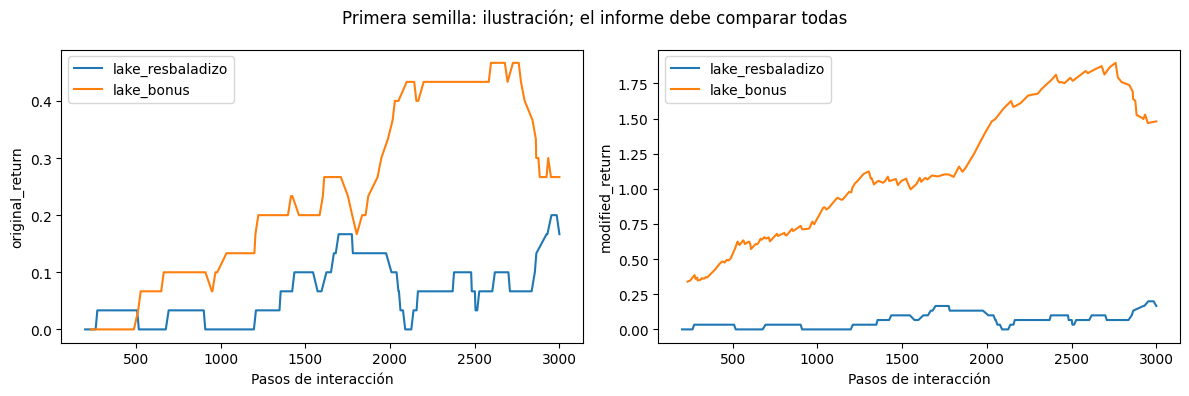

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ["lake_resbaladizo", "lake_bonus"]:
    history = results["scenarios"][name]["runs"][0]["train_history"]
    x = [h["steps"] for h in history]
    window = min(30, len(history))
    for ax, metric in zip(axes, ["original_return", "modified_return"]):
        y = np.convolve([h[metric] for h in history], np.ones(window)/window, mode="valid")
        ax.plot(x[window-1:], y, label=name)
        ax.set(xlabel="Pasos de interacción", ylabel=metric)
        ax.legend()
plt.suptitle("Primera semilla: ilustración; el informe debe comparar todas")
plt.tight_layout()
plt.show()


## 4. Auditar propuestas

Para cada propuesta, identificar la causa, construir un contraejemplo, corregir y verificar. No comparar solo curvas: pueden ocultar el defecto.

In [6]:
def propuesta_a(q, s, a, r, ns, terminated, truncated, alpha, gamma):
    target = r + gamma * (not terminated) * np.argmax(q[ns])
    return q[s, a] + alpha * (target - q[s, a])

def propuesta_b(q, s, a, r, ns, terminated, truncated, alpha, gamma):
    target = r + gamma * (not (terminated or truncated)) * np.max(q[ns])
    return q[s, a] + alpha * (target - q[s, a])

probe = np.array([[0., 0., 0., 0.], [8., 1., 0., 0.]])
print("A, target usando argmax:", propuesta_a(probe, 0, 0, 0., 1, False, False, 1., .9))
print("Correcto:", q_update(probe, 0, 0, 0., 1, False, False, 1., .9))
probe[1, 0] = 10.
print("B, truncación externa:", propuesta_b(probe, 0, 0, 1., 1, False, True, 1., .9))
print("Correcto:", q_update(probe, 0, 0, 1., 1, False, True, 1., .9))
numerical_checks(q_update)


A, target usando argmax: 0.0
Correcto: 7.2
B, truncación externa: 1.0
Correcto: 10.0
Tres contraejemplos numéricos verificados.


## 5. Una trayectoria para interpretar el bonus

Cargar una Q-table guardada de `lake_bonus`, usar `make_env`, `reset(seed=...)` y `greedy`. Registrar estado, acción, siguiente estado, retorno original y si termina/trunca. No entrenar durante ese rollout. Comparar con `lake_resbaladizo` usando el mismo reset seed.

In [7]:
from experimentos import trace_policy
for name in ["lake_resbaladizo", "lake_bonus"]:
    artifact = BASE / "outputs" / (MODE + "_" + SPLIT) / (name + "_11.npz")
    q = np.load(artifact)["q"]
    trace = trace_policy(q, seed=1000000)
    print(name, "retorno original", sum(t["reward"] for t in trace), "pasos", len(trace))
    print("Primeras 15 transiciones:", trace[:15])


lake_resbaladizo retorno original 0.0 pasos 6
Primeras 15 transiciones: [{'state': 0, 'action': 0, 'next_state': 0, 'reward': 0.0, 'terminated': False, 'truncated': False}, {'state': 0, 'action': 0, 'next_state': 0, 'reward': 0.0, 'terminated': False, 'truncated': False}, {'state': 0, 'action': 0, 'next_state': 4, 'reward': 0.0, 'terminated': False, 'truncated': False}, {'state': 4, 'action': 0, 'next_state': 8, 'reward': 0.0, 'terminated': False, 'truncated': False}, {'state': 8, 'action': 3, 'next_state': 9, 'reward': 0.0, 'terminated': False, 'truncated': False}, {'state': 9, 'action': 2, 'next_state': 5, 'reward': 0.0, 'terminated': True, 'truncated': False}]
lake_bonus retorno original 1.0 pasos 46
Primeras 15 transiciones: [{'state': 0, 'action': 0, 'next_state': 0, 'reward': 0.0, 'terminated': False, 'truncated': False}, {'state': 0, 'action': 0, 'next_state': 0, 'reward': 0.0, 'terminated': False, 'truncated': False}, {'state': 0, 'action': 0, 'next_state': 4, 'reward': 0.0, 't

## 6. Cierre formativo

Compartir una observación y una decisión verificada, con o sin IA. Distinguir recompensa modificada, retorno original y éxito. ¿Cuánto depende la conclusión de la semilla? ¿Qué cambió realmente en la política? La hoja de trabajo es opcional y no se entrega.
